# EchoTrain tutorial: from field recordings to a trained classifier

This notebook walks through the whole EchoTrain workflow on a small dataset
that ships with the repository: **70 field recordings of 5 European frog
species** (22 minutes of audio). Everything runs in a few minutes on a GPU.

1. **The recordings**: what is in the dataset, listen to a few.
2. **Cut the recordings into chunks** with `tools/prepare_chunks.py`.
3. **The chunk dataset** that the model trains on.
4. **Listen and look**: waveforms and the spectrogram the model actually sees.
5. **Map the data before training**: UMAP of spectrogram features and of two pre-trained networks.
6. **Train** a model with `train.py`, exactly as you would from the terminal.
7. **Read the training results**: learning curves, per-class scores, confusions.
8. **Evaluate on the test set** with `evaluate.py`.
9. **Try a second model** by changing one option, and compare.
10. **Map the data after training**: the same UMAP with the trained networks.
11. **Use the model** on a whole recording.

Section 12 explains how to do the same with your own data.

### Running this notebook

From the repository root:

```bash
uv sync --group notebook                                          # once: Jupyter, UMAP
uv run --group notebook jupyter lab notebooks/tutorial_toy_frogs.ipynb
```

## 0. Setup

The notebook works from the repository root, so that the paths in the config
and the scripts (`train.py`, `evaluate.py`, `tools/prepare_chunks.py`) resolve.

In [1]:
import contextlib
import io
import json
import os
import shutil
import sys
import time
import warnings
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import umap
from IPython.display import Audio, Markdown, display
from sklearn.metrics import ConfusionMatrixDisplay, balanced_accuracy_score, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier

# Work from the repository root (the folder that holds train.py).
ROOT = Path.cwd().resolve()
while not (ROOT / "train.py").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Start Jupyter inside the echotrain repository.")
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# Quieter logs from the scripts when they run inside the notebook.
os.environ["TQDM_DISABLE"] = "1"
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
# Spectrograms are large as PNG; JPEG keeps the saved notebook small.
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}
print("repository:", ROOT)

repository: /data/burooj/test/echotrain


The EchoTrain modules (importable now that the repository root is on the path)
and the paths used throughout:

In [2]:
from echotrain.data import LabelSpace, build_label_space, read_split
from echotrain.dataset import fix_length
from echotrain.frontend import PerchFrontend
from echotrain.model_zoo import build_model
from echotrain.options import load_config

REC_DIR = Path("data/toy_frogs/recordings")    # the full recordings (in the repository)
CHUNK_DIR = Path("data/toy_frogs_chunks")       # the chunks, made in section 2
CONFIG = "configs/toy_frogs.yaml"
TEST_DIR = CHUNK_DIR / "test"
cfg = load_config(CONFIG)
SR = cfg["audio"]["sample_rate"]
CHUNK_SECONDS = cfg["audio"]["clip_seconds"]
N_SAMPLES = int(CHUNK_SECONDS * SR)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 1. The recordings

`data/toy_frogs/recordings` holds the full recordings, in the class-folder
layout: one folder per split, one subfolder per species. The folder name is
the class name.

```
data/toy_frogs/recordings/
  train/Bombina_bombina/inat_INAT156488836_655321.ogg
  train/Bufo_bufo/...
  val/...
  test/...
```

The recordings were made by volunteers and shared on
[iNaturalist](https://www.inaturalist.org) under open licences (CC0, CC BY,
CC BY-SA). `data/toy_frogs/recordings.csv` lists every file with its
recordist, licence and a link to the observation:

In [3]:
recs = pd.read_csv("data/toy_frogs/recordings.csv")
recs["path"] = [str(REC_DIR / p) for p in recs.file_path]
recs.drop(columns="path").head()

,file_path,latin,split,duration_s,sample_rate,source,recordist,licence,url,date,location
0,train/Bombina_bombina/inat_INAT156488836_65532...,Bombina bombina,train,12.80,48000,iNaturalist,tomegatherion,CC BY,https://www.inaturalist.org/observations/15648...,2023-04-24,"Кстовский р-н, Нижегородская обл., Россия"
1,train/Bombina_bombina/inat_INAT166455457_73187...,Bombina bombina,train,16.09,44100,iNaturalist,trolleway,CC0,https://www.inaturalist.org/observations/16645...,2023-06-09,"Московская обл., Россия, 140127"
2,train/Bombina_bombina/inat_INAT180434785_80094...,Bombina bombina,train,8.07,44100,iNaturalist,twan3253,CC BY,https://www.inaturalist.org/observations/18043...,2023-06-14,"Hortobágy, 4071 Hungary"
3,train/Bombina_bombina/inat_INAT204364731_94357...,Bombina bombina,train,5.24,44100,iNaturalist,emilvus,CC BY,https://www.inaturalist.org/observations/20436...,2024-03-27,"16 Angermünde, Deutschland"
4,train/Bombina_bombina/inat_INAT218064106_10575...,Bombina bombina,train,15.93,44100,iNaturalist,lennarthud,CC BY,https://www.inaturalist.org/observations/21806...,2024-05-25,"Niedersachsen, DE"


The data is split **by recording** into train, validation and test. Everything
cut from one recording stays in its split: chunks of one recording sound alike
(same frog, same microphone, same background), so splitting a recording across
train and test would make the test score look better than it is.

,train recordings,val recordings,test recordings,train seconds,val seconds,test seconds
latin,,,,,,
Bombina bombina,8,3,3,157,71,38
Bufo bufo,8,3,3,172,46,129
Epidalea calamita,8,3,3,160,44,70
Hyla arborea,8,3,3,130,30,32
Hyla meridionalis,8,3,3,130,70,34


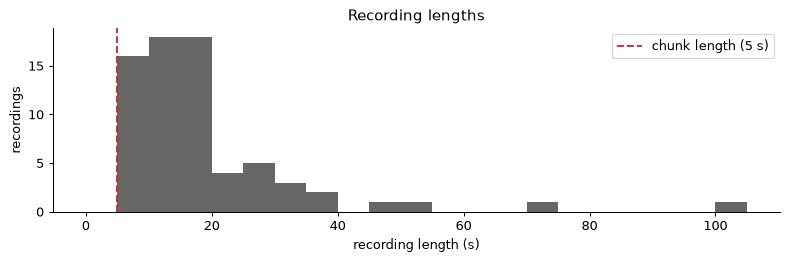

In [4]:
counts = recs.pivot_table(index="latin", columns="split", values="duration_s",
                          aggfunc=["count", "sum"])[[("count", s) for s in ("train", "val", "test")] +
                                                     [("sum", s) for s in ("train", "val", "test")]]
counts.columns = [f"{s} {'recordings' if a == 'count' else 'seconds'}" for a, s in counts.columns]
display(counts.round(0).astype(int))

fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(recs.duration_s, bins=np.arange(0, recs.duration_s.max() + 5, 5), color="0.4")
ax.axvline(CHUNK_SECONDS, color="C3", ls="--", label=f"chunk length ({CHUNK_SECONDS:g} s)")
ax.set(xlabel="recording length (s)", ylabel="recordings", title="Recording lengths")
ax.legend()
fig.tight_layout()

The recordings are 5 s to 2 minutes long and come with different sample rates
(32, 44.1 and 48 kHz). Listen to one recording per species (the first 15 s; chosen because the
frog is easy to hear, many recordings are noisier):

In [5]:
EXAMPLES = ["train/Bombina_bombina/inat_INAT156488836_655321.ogg",
            "train/Bufo_bufo/inat_INAT348277741_1847340.ogg",
            "train/Epidalea_calamita/inat_INAT223847583_1101161.ogg",
            "train/Hyla_arborea/inat_INAT357734175_1921928.ogg",
            "train/Hyla_meridionalis/inat_INAT347637792_1842568.ogg"]
listen = recs.set_index("file_path").loc[EXAMPLES].reset_index()

def snippet(path, seconds=10):
    # The first seconds of a file as a small OGG player (keeps the saved notebook small).
    x, _ = librosa.load(path, sr=SR, duration=seconds)
    buf = io.BytesIO()
    sf.write(buf, x, SR, format="OGG", subtype="VORBIS")
    audio = Audio(data=buf.getvalue())
    audio.mimetype = "audio/ogg"
    return audio

for _, r in listen.iterrows():
    display(Markdown(f"**{r.latin}**, {r.duration_s:.0f} s, recorded by {r.recordist} "
                     f"({r.licence}, [observation]({r.url}))"))
    display(snippet(r.path, seconds=15))

**Bombina bombina**, 13 s, recorded by tomegatherion (CC BY, [observation](https://www.inaturalist.org/observations/156488836))

**Bufo bufo**, 16 s, recorded by f_s (CC BY, [observation](https://www.inaturalist.org/observations/348277741))

**Epidalea calamita**, 18 s, recorded by lennarthud (CC BY, [observation](https://www.inaturalist.org/observations/223847583))

**Hyla arborea**, 11 s, recorded by sven_gippner (CC BY, [observation](https://www.inaturalist.org/observations/357734175))

**Hyla meridionalis**, 25 s, recorded by paolasiligardi (CC0, [observation](https://www.inaturalist.org/observations/347637792))

## 2. Cut the recordings into chunks

The model trains on pieces of a fixed length (`audio.clip_seconds`, 5 s
here). A longer file would be cropped, so most of it would never be seen;
a shorter one would be repeated to fill the length. So the recordings are first
cut into **chunks** of that length with `tools/prepare_chunks.py`:

- every recording is mixed to mono and resampled to 32 kHz (`--target-sr`, the
  model's `audio.sample_rate`);
- it is cut into consecutive 5 s chunks (`--chunk-seconds`);
- a leftover at the end that is at least 2 s long (`--min-chunk-seconds`) is
  repeated (tiled) up to 5 s and kept as a last chunk; a shorter leftover is
  dropped. A recording shorter than 5 s always gives one tiled chunk.

With class folders as input (`--input-dir`), the tool writes the chunks as
`.wav` files in the same class-folder layout, named
`<recording>_chunk000.wav`, `<recording>_chunk001.wav`, ... It runs once
per split. In a terminal:

```bash
uv run tools/prepare_chunks.py --input-dir data/toy_frogs/recordings/train --split train \
    --output-dir data/toy_frogs_chunks/train --output-manifest data/toy_frogs_chunks/train.csv --chunk-seconds 5
```

Here, for all three splits:

In [6]:
shutil.rmtree(CHUNK_DIR, ignore_errors=True)       # start fresh, so no chunks from an earlier run remain
for split in ["train", "val", "test"]:  # noqa: B007 (split is used in the shell command)
    !{sys.executable} tools/prepare_chunks.py --input-dir {REC_DIR / split} --split {split} \
        --output-dir {CHUNK_DIR / split} --output-manifest {CHUNK_DIR / split}.csv --chunk-seconds {CHUNK_SECONDS}

2026-11-06 17:44:54,313 [INFO] 40 recordings -> data/toy_frogs_chunks/train


2026-11-06 17:44:57,244 [INFO] 152 chunks written. Manifest: data/toy_frogs_chunks/train.csv
2026-11-06 17:44:57,245 [INFO] Chunks per split:
split
train    152


2026-11-06 17:44:57,720 [INFO] 15 recordings -> data/toy_frogs_chunks/val


2026-11-06 17:44:59,987 [INFO] 54 chunks written. Manifest: data/toy_frogs_chunks/val.csv
2026-11-06 17:44:59,990 [INFO] Chunks per split:
split
val    54


2026-11-06 17:45:00,521 [INFO] 15 recordings -> data/toy_frogs_chunks/test


2026-11-06 17:45:02,694 [INFO] 62 chunks written. Manifest: data/toy_frogs_chunks/test.csv
2026-11-06 17:45:02,697 [INFO] Chunks per split:
split
test    62


The tool writes two things:

1. **the chunk files**, in the class-folder layout. This is what the config uses
   (`data.mode: folders`, `data.train_dir: data/toy_frogs_chunks/train`, ...);
2. **a CSV per split** with one row per chunk: the source recording
   (`file_path`), the class (`latin`), the split and the chunk's path. It is not
   needed for training with class folders.

In [7]:
for p in sorted((CHUNK_DIR / "train" / "Hyla_arborea").iterdir())[:6]:
    print(p)
print("...")
pd.read_csv(CHUNK_DIR / "train.csv").head(3)

data/toy_frogs_chunks/train/Hyla_arborea/inat_INAT156056456_652335_chunk000.wav
data/toy_frogs_chunks/train/Hyla_arborea/inat_INAT163177896_708606_chunk000.wav
data/toy_frogs_chunks/train/Hyla_arborea/inat_INAT163177896_708606_chunk001.wav
data/toy_frogs_chunks/train/Hyla_arborea/inat_INAT167927941_742231_chunk000.wav
data/toy_frogs_chunks/train/Hyla_arborea/inat_INAT167927941_742231_chunk001.wav
data/toy_frogs_chunks/train/Hyla_arborea/inat_INAT167927941_742231_chunk002.wav
...


,file_path,latin,split,chunk_path
0,data/toy_frogs/recordings/train/Bombina_bombin...,Bombina_bombina,train,train/Bombina_bombina/inat_INAT156488836_65532...
1,data/toy_frogs/recordings/train/Bombina_bombin...,Bombina_bombina,train,train/Bombina_bombina/inat_INAT156488836_65532...
2,data/toy_frogs/recordings/train/Bombina_bombin...,Bombina_bombina,train,train/Bombina_bombina/inat_INAT156488836_65532...


> **Alternative: a manifest.** `recordings.csv` has a `split` column, so it can
> be used as a manifest (Option B in the README) and all splits are chunked in one
> run:
> ```bash
> uv run tools/prepare_chunks.py --manifest data/toy_frogs/recordings.csv --audio-root data/toy_frogs/recordings \
>     --output-dir data/toy_frogs_chunks_m --output-manifest data/toy_frogs_chunks_m.csv --chunk-seconds 5 --flat
> ```
> The output CSV is then the training manifest (`data.mode: manifest`,
> `path_col: chunk_path`, `group_col: file_path`).

**What happened to one recording.** The plot shows a recording with its chunk
boundaries and the leftover at the end:

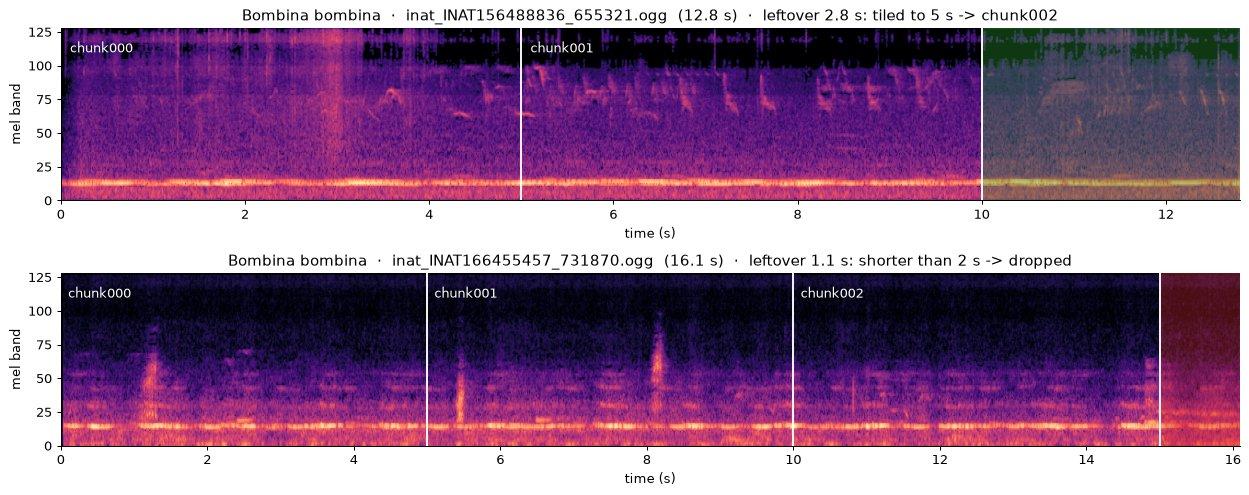

In [8]:
def logmel_db(x):
    # Log-mel spectrogram for plots: 128 bands up to 16 kHz.
    S = librosa.feature.melspectrogram(y=x, sr=SR, n_fft=1024, hop_length=320, n_mels=128, fmax=16000)
    return librosa.power_to_db(S, ref=np.max)

# a recording whose leftover is kept (2-5 s) and one whose leftover is dropped (< 2 s)
rem = recs.duration_s % CHUNK_SECONDS
picks = [recs[(recs.split == "train") & (rem >= 2) & (recs.duration_s.between(10, 25))].iloc[0],
         recs[(recs.split == "train") & (rem < 2) & (recs.duration_s.between(10, 25))].iloc[0]]

fig, axes = plt.subplots(len(picks), 1, figsize=(14, 2.8 * len(picks)))
for ax, r in zip(axes, picks, strict=True):
    x, _ = librosa.load(r.path, sr=SR)
    dur = len(x) / SR
    ax.imshow(logmel_db(x), origin="lower", aspect="auto", cmap="magma", vmin=-80, extent=[0, dur, 0, 128])
    n_full = int(dur // CHUNK_SECONDS)
    for i in range(n_full):
        ax.axvline(i * CHUNK_SECONDS, color="w", lw=1.5)
        ax.text(i * CHUNK_SECONDS + 0.1, 118, f"chunk{i:03d}", color="w", fontsize=10, va="top")
    left = dur - n_full * CHUNK_SECONDS
    ax.axvline(n_full * CHUNK_SECONDS, color="w", lw=1.5)
    kept = left >= 2
    ax.axvspan(n_full * CHUNK_SECONDS, dur, color="C2" if kept else "C3", alpha=0.35)
    fate = f"tiled to 5 s -> chunk{n_full:03d}" if kept else "shorter than 2 s -> dropped"
    ax.set(title=f"{r.latin}  ·  {Path(r.path).name}  ({dur:.1f} s)  ·  leftover {left:.1f} s: {fate}",
           ylabel="mel band", xlabel="time (s)")
fig.tight_layout()

The kept leftover becomes a chunk by repeating it until it is 5 s long:

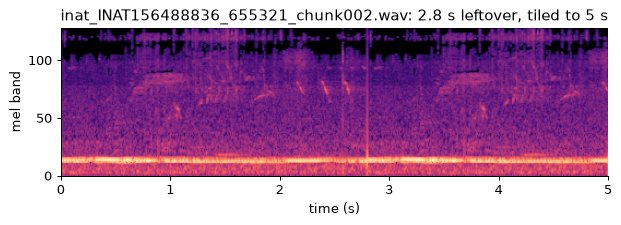

In [9]:
r = picks[0]
n_full = int(r.duration_s // CHUNK_SECONDS)
last = CHUNK_DIR / r.split / r.latin.replace(" ", "_") / f"{Path(r.path).stem}_chunk{n_full:03d}.wav"
x, _ = librosa.load(last, sr=SR)
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.imshow(logmel_db(x), origin="lower", aspect="auto", cmap="magma", vmin=-80, extent=[0, 5, 0, 128])
ax.set(title=f"{last.name}: {r.duration_s - n_full * CHUNK_SECONDS:.1f} s leftover, tiled to 5 s",
       xlabel="time (s)", ylabel="mel band")
fig.tight_layout()

## 3. The chunk dataset

From here on, everything works on the chunks. This is the config used for
training:

In [10]:
print(Path(CONFIG).read_text())

# Toy dataset of 5 European frog species, used by notebooks/tutorial_toy_frogs.ipynb.
# The repository has the full recordings (data/toy_frogs/recordings); cut them
# into 5 s chunks first (the tutorial does this), then train. From the repository root:
#   for s in train val test; do
#     uv run tools/prepare_chunks.py --input-dir data/toy_frogs/recordings/$s --split $s \
#       --output-dir data/toy_frogs_chunks/$s --output-manifest data/toy_frogs_chunks/$s.csv --chunk-seconds 5
#   done
#   uv run train.py --config configs/toy_frogs.yaml
# Every option and its default is listed in echotrain/options.py.

run_name: toy_frogs
output_dir: runs
device: cuda:0             # falls back to the CPU if there is no GPU

data:
  mode: folders            # one subfolder per species
  train_dir: data/toy_frogs_chunks/train
  val_dir: data/toy_frogs_chunks/val

audio:
  sample_rate: 32000
  clip_seconds: 5          # the chunks are 5 s long

taxonomy:
  genus_head: true         # 4 genera: Bombin

`read_split` is what `train.py` uses to list a split. It returns the file
paths, their labels, and the recording ("group") each chunk belongs to: the
file name without the `_chunk003` suffix. In evaluation, the model's scores for
the chunks of one recording are max-pooled, so that the scores are **per
recording**.

In [11]:
splits = {"train": read_split(cfg, "train"), "val": read_split(cfg, "val"), "test": read_split(cfg, TEST_DIR)}
files = pd.concat(
    [pd.DataFrame({"split": name, "path": s.paths, "species": s.labels, "recording": s.groups})
     for name, s in splits.items()],
    ignore_index=True)
files["path"] = files["path"].astype(str)

summary = files.groupby(["species", "split"]).agg(chunks=("path", "size"), recordings=("recording", "nunique"))
summary = summary.unstack("split").reorder_levels([1, 0], axis=1)[["train", "val", "test"]]
display(summary)
print(f"{len(files)} chunks from {files.recording.nunique()} recordings")

split              train               val              test           
                  chunks recordings chunks recordings chunks recordings
species                                                                
Bombina_bombina       32          8     15          3      8          3
Bufo_bufo             34          8     10          3     26          3
Epidalea_calamita     34          8      9          3     15          3
Hyla_arborea          26          8      6          3      6          3
Hyla_meridionalis     26          8     14          3      7          3

268 chunks from 70 recordings


The number of chunks per species differs, because the recordings differ in
length. In training, `sampler.balanced` draws chunks of rare classes more often
to make up for it.

The class list and the parent group ("genus") of each class come from the
training folders. With `taxonomy.genus_head: true` the model also predicts the
genus; here the genus is the first word of the folder name.

In [12]:
label_space = build_label_space(cfg, splits["train"])
SPECIES = label_space.species
pd.DataFrame({"species": SPECIES, "genus": [label_space.species_to_genus[s] for s in SPECIES]})

,species,genus
0,Bombina_bombina,Bombina
1,Bufo_bufo,Bufo
2,Epidalea_calamita,Epidalea
3,Hyla_arborea,Hyla
4,Hyla_meridionalis,Hyla


## 4. Listen and look

The first chunk of each recording you listened to in section 1. Each row shows
the waveform, an ordinary spectrogram (linear frequency axis, so you can read
off kHz), and the **log-mel spectrogram the model gets as input**. That last
one is computed by `echotrain/frontend.py` inside the model: 128 mel bands from
60 Hz to 16 kHz, 10 ms per frame.

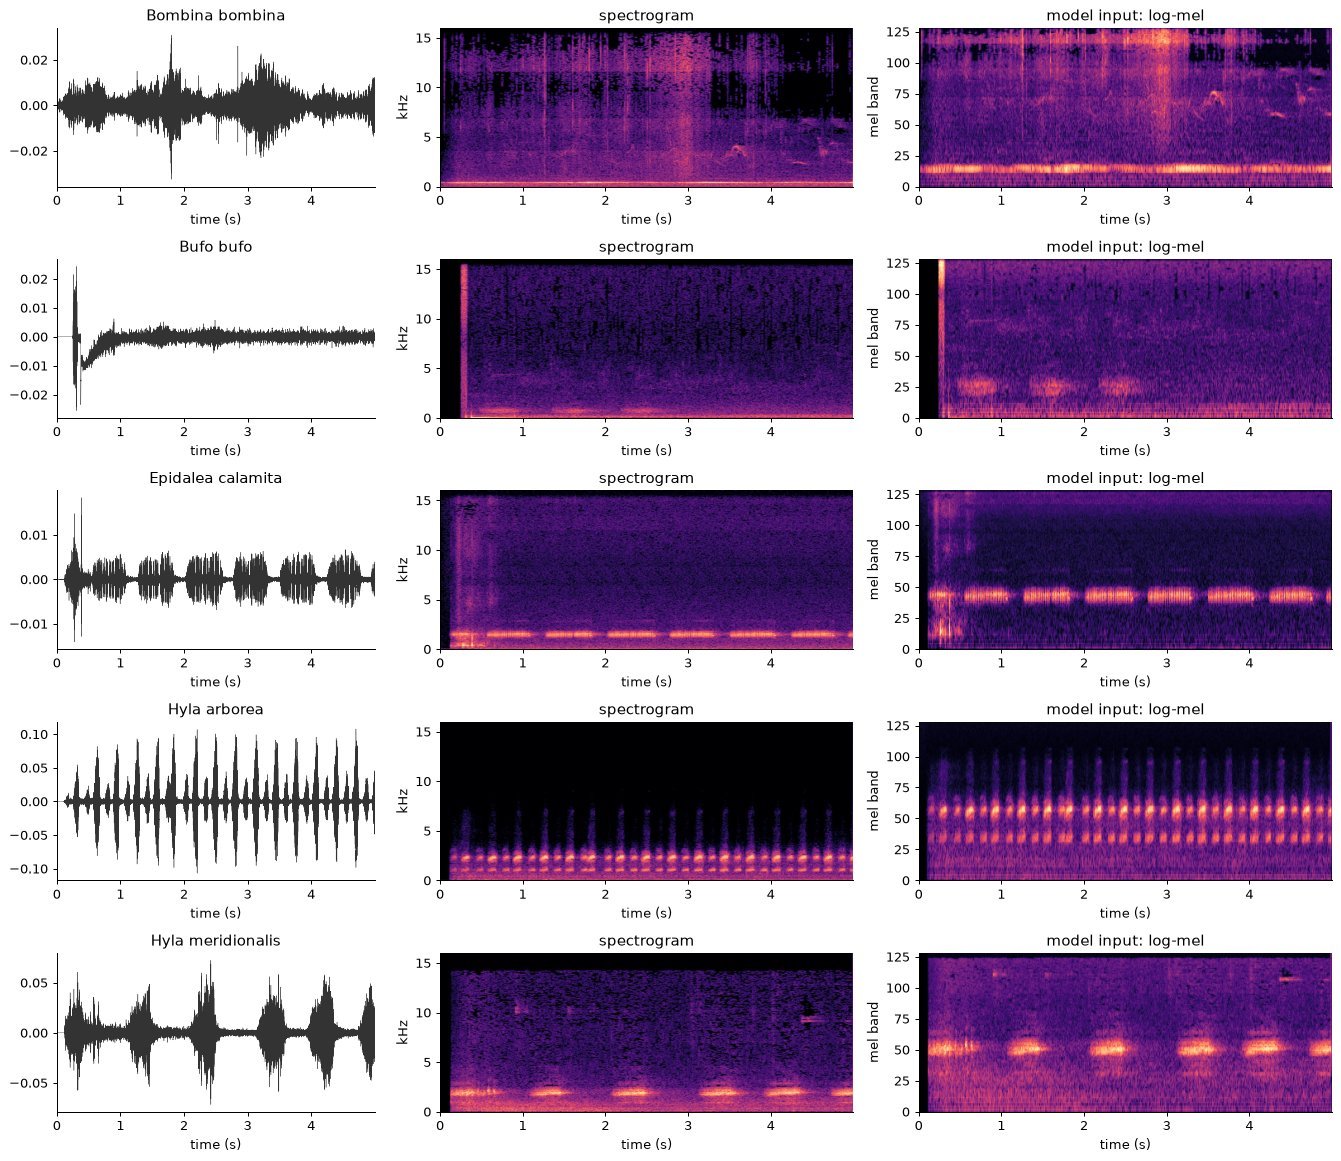

In [13]:
frontend = PerchFrontend(sr=SR, **{k: cfg["frontend"][k] for k in ("n_mels", "fmin", "fmax")}).eval()

def load(path):
    # Load at the model's sample rate and crop/tile to the chunk length, as the training data loader does.
    x, _ = librosa.load(path, sr=SR, mono=True)
    return fix_length(x, N_SAMPLES, random_crop=False)

def logmel(x):
    with torch.no_grad():
        return frontend(torch.as_tensor(x, dtype=torch.float32)[None])[0].numpy()  # (time, n_mels)

examples = [(r.latin, CHUNK_DIR / "train" / r.latin.replace(" ", "_") / f"{Path(r.path).stem}_chunk000.wav")
            for _, r in listen.iterrows()]

fig, axes = plt.subplots(len(examples), 3, figsize=(15, 2.6 * len(examples)),
                         gridspec_kw={"width_ratios": [1, 1.3, 1.3]})
t = np.arange(N_SAMPLES) / SR
for ax, (sp, path) in zip(axes, examples, strict=True):
    x = load(path)
    ax[0].plot(t, x, lw=0.3, color="0.2")
    ax[0].set(title=sp, xlabel="time (s)", xlim=(0, t[-1]))

    S = librosa.amplitude_to_db(np.abs(librosa.stft(x, n_fft=1024, hop_length=256)), ref=np.max)
    ax[1].imshow(S, origin="lower", aspect="auto", cmap="magma", vmin=-80, extent=[0, t[-1], 0, SR / 2 / 1000])
    ax[1].set(title="spectrogram", xlabel="time (s)", ylabel="kHz")

    ax[2].imshow(logmel(x).T, origin="lower", aspect="auto", cmap="magma", extent=[0, t[-1], 0, 128])
    ax[2].set(title="model input: log-mel", xlabel="time (s)", ylabel="mel band")
fig.tight_layout()

Each species has its own pitch and rhythm:

- *Bombina bombina*: a soft, low, continuous note near 0.5 kHz (the band at the bottom; birds call above it);
- *Bufo bufo*: a few short, quiet notes around 0.7 kHz (after a click at the start of the recording);
- *Epidalea calamita*: regular trills of about half a second near 1.5 kHz;
- *Hyla arborea*: a fast train of pulses, about four per second, at 1 and 2.3 kHz;
- *Hyla meridionalis*: slower, longer notes near 2 kHz, about one per second.

These are good examples; in many chunks the frog is fainter, farther away, or
mixed with wind, birds, insects and other frogs.

**Average spectrum per species.** Averaging the log-mel spectrogram over time
and over all training chunks of a species gives its typical frequency profile:

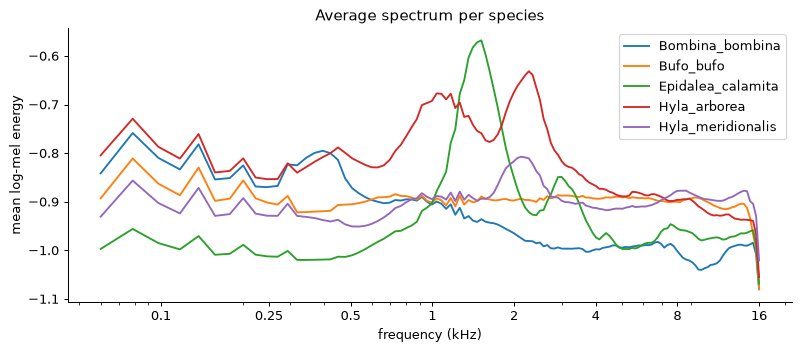

In [14]:
mel_freqs = librosa.mel_frequencies(n_mels=cfg["frontend"]["n_mels"], fmin=cfg["frontend"]["fmin"],
                                    fmax=cfg["frontend"]["fmax"], htk=True)
mels = {p: logmel(load(p)) for p in files.path}          # cache: (time, n_mels) per chunk
fig, ax = plt.subplots(figsize=(9, 4))
for sp, grp in files[files.split == "train"].groupby("species"):
    profile = np.mean([mels[p].mean(0) for p in grp.path], axis=0)
    ax.plot(mel_freqs / 1000, profile, label=sp)
ax.set(xscale="log", xlabel="frequency (kHz)", ylabel="mean log-mel energy", title="Average spectrum per species")
ax.set_xticks([0.1, 0.25, 0.5, 1, 2, 4, 8, 16], ["0.1", "0.25", "0.5", "1", "2", "4", "8", "16"])
ax.legend()
fig.tight_layout()

The averages agree with the examples: *Epidalea calamita* has a sharp peak at
1.5 kHz, *Hyla arborea* two peaks near 1.1 and 2.3 kHz, *Hyla meridionalis*
one near 2.2 kHz, and *Bombina bombina* a bump at 0.4 kHz. *Bufo bufo* has no
clear peak: its calls are quiet and short and disappear in the background
noise when averaged. Pitch alone does not separate all species; the timing
of the calls (pulse rate, note length) matters too, and that is what the model
can learn from the spectrogram.

## 5. The data before training: UMAP

How well can the species be told apart *before* any training? We turn every
chunk into a feature vector and project the vectors to 2-D with
[UMAP](https://umap-learn.readthedocs.io/), which keeps similar chunks close
together. Three kinds of features:

- **Spectrogram statistics**: the mean and standard deviation of each mel
  band over time (256 numbers per chunk). No learning at all.
- **ImageNet EfficientNet-B0**: the network of `configs/toy_frogs.yaml` with
  its ImageNet weights (trained on photos, never on sound). The vector is the
  1280-d output of the backbone, just before the classification heads.
- **Perch EfficientNet-B3**: the `perch_effnet_b3` model, with the weights of
  [Perch v2](https://arxiv.org/abs/2508.04665), a network trained by Google on
  a large collection of animal sounds (birds, frogs, insects, mammals). 1536-d.

A number to go with the pictures: **k-nearest-neighbour accuracy**. Each test
chunk gets the majority species of its 5 nearest training chunks; we report the
*balanced* accuracy (the mean of the per-species accuracies), because one long
*Bufo bufo* recording makes up 26 of the 62 test chunks. Chance is 20 %.

In [15]:
def backbone_embeddings(model, paths, batch_size=32):
    # Output of the backbone (before the species/genus heads), one vector per chunk.
    model.eval().to(device)
    out = []
    with torch.no_grad():
        for i in range(0, len(paths), batch_size):
            x = torch.as_tensor(np.stack([load(p) for p in paths[i:i + batch_size]]), device=device)
            out.append(model.backbone(model.mel(x).unsqueeze(1)).float().cpu())
    return torch.cat(out).numpy()

def knn_accuracy(features):
    train, test = (files.split == "train").values, (files.split == "test").values
    knn = KNeighborsClassifier(n_neighbors=5, metric="cosine").fit(features[train], files.species[train])
    return balanced_accuracy_score(files.species[test], knn.predict(features[test]))

def umap_2d(features):
    return umap.UMAP(n_neighbors=15, min_dist=0.2, metric="cosine", random_state=0).fit_transform(features)

COLORS = dict(zip(SPECIES, plt.cm.tab10.colors, strict=False))
MARKERS = {"train": "o", "val": "^", "test": "s"}

def plot_map(ax, xy, title):
    for sp in SPECIES:
        for split, marker in MARKERS.items():
            m = ((files.species == sp) & (files.split == split)).values
            ax.scatter(xy[m, 0], xy[m, 1], s=22 if split == "train" else 36, marker=marker,
                       color=COLORS[sp], alpha=0.75, edgecolor="none" if split == "train" else "k", lw=0.4,
                       label=sp if split == "train" else None)
    ax.set(title=title, xticks=[], yticks=[])

def plot_maps(names):
    fig, axes = plt.subplots(1, len(names), figsize=(6.6 * len(names), 6.3))
    for ax, name in zip(np.atleast_1d(axes), names, strict=True):
        plot_map(ax, maps[name], f"{name}\n5-NN balanced test accuracy {knn_accuracy(features[name]):.0%}")
    np.atleast_1d(axes)[0].legend(loc="best", fontsize=8)
    fig.text(0.5, 0.01, "dots: train  ·  triangles: val  ·  squares: test", ha="center")
    fig.tight_layout(rect=(0, 0.03, 1, 1))

def quiet(fn, *args, **kwargs):
    # Run fn without its printed output (the Perch model prints its weight loading).
    with contextlib.redirect_stdout(io.StringIO()):
        return fn(*args, **kwargs)

paths = files.path.tolist()
features = {"spectrogram statistics": np.stack([np.concatenate([mels[p].mean(0), mels[p].std(0)]) for p in paths])}
features["ImageNet EfficientNet-B0"] = backbone_embeddings(build_model(cfg, label_space), paths)
perch_cfg = load_config(CONFIG, ["model.name=perch_effnet_b3"])
features["Perch EfficientNet-B3"] = backbone_embeddings(quiet(build_model, perch_cfg, label_space), paths)

for name, f in features.items():
    print(f"{name:26s} {f.shape[1]:5d}-d   5-NN balanced test accuracy {knn_accuracy(f):.0%}")

spectrogram statistics       256-d   5-NN balanced test accuracy 17%
ImageNet EfficientNet-B0    1280-d   5-NN balanced test accuracy 39%
Perch EfficientNet-B3       1536-d   5-NN balanced test accuracy 85%


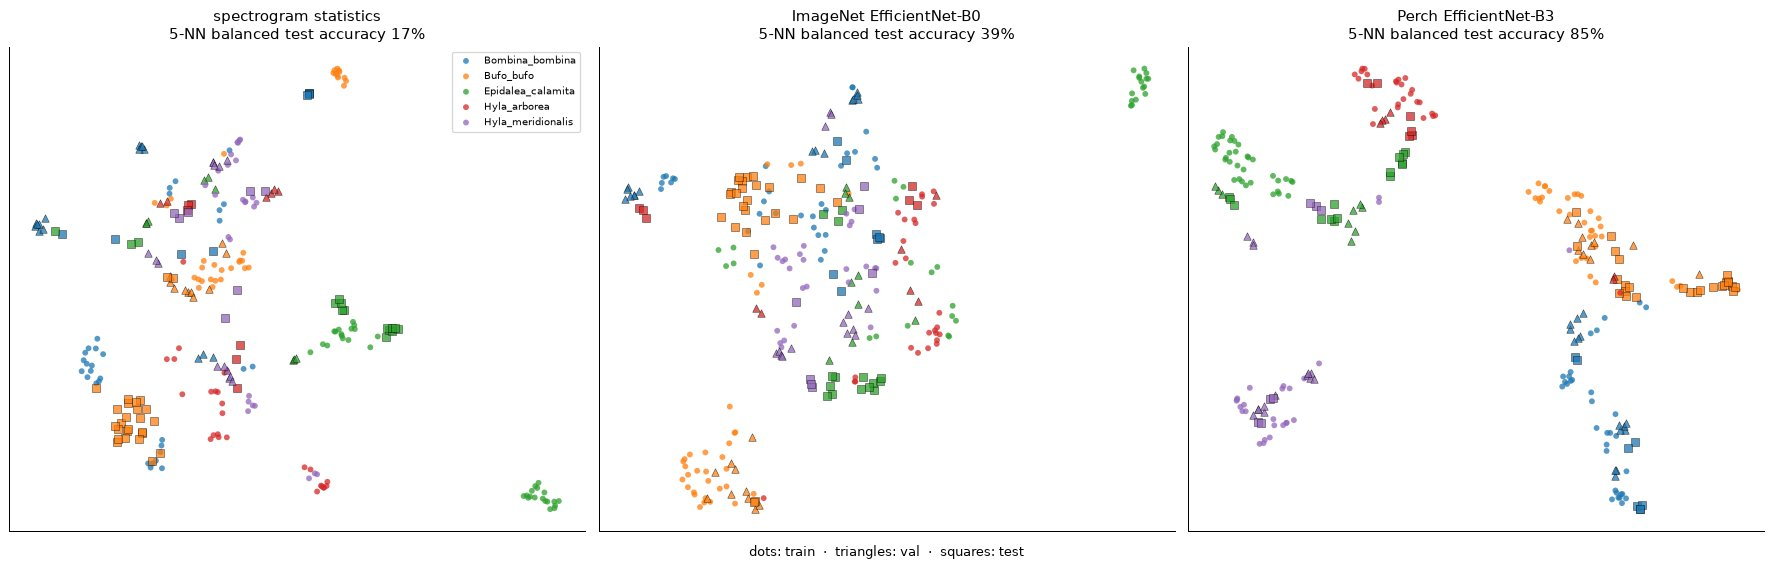

In [16]:
maps = {name: umap_2d(f) for name, f in features.items()}
plot_maps(list(maps))

- **Spectrogram statistics** do no better than chance. Their small, tight
  groups are recordings, not species: the chunks of one recording share the
  same background noise and microphone, and a test recording has no such twin
  in the training set.
- The **ImageNet** network separates a few species (*Bufo bufo* at the
  bottom, part of *Epidalea calamita*) but mixes most of them.
- The **Perch** network, trained on animal sounds, already groups the chunks
  by species before it has seen any of this data, and most validation and test
  chunks fall into the right group.

So before training a single epoch, the choice of starting weights already
matters a lot. Training should improve the ImageNet network the most.

## 6. Train

Training is done by `train.py`, the same command you would type in a
terminal (there, with `uv run` in front):

```bash
uv run train.py --config configs/toy_frogs.yaml
```

Here it runs as a subprocess of the notebook. Any option can be changed with
`--set section.key=value` without editing the config; we give the run a name
with a timestamp so that each run of this notebook gets its own folder in
`runs/`.

What happens in each epoch:

- the training chunks are drawn class-balanced (`sampler.balanced`), with
  mixup (10 % of the batches mix two chunks and label them with both species)
  and SpecAugment masking of the spectrogram;
- the loss is binary cross-entropy for the species head plus the genus head;
- the validation chunks are scored, pooled per recording, and the mAP is
  computed; the weights of the epoch with the best validation mAP are kept
  as `best_model.pt`.

The `effnet` model with `efficientnet_b0` takes a few seconds per epoch on a GPU.

In [17]:
STAMP = time.strftime("%Y%m%d-%H%M%S")
RUN_DIR = Path(cfg["output_dir"]) / f"toy_frogs_{STAMP}"
!{sys.executable} train.py --config {CONFIG} --set run_name={RUN_DIR.name}

Run directory: runs/toy_frogs_20261106-174518  |  device: cuda:0
[train] 152 files, 40 recordings, 5 classes (smallest: 26, largest: 34)
[val] 54 files, 15 recordings, 5 classes (smallest: 6, largest: 15)
5 classes, 4 genera


Model effnet: 4.0M trainable parameters


Epoch 1/20  train_loss 1.2367  val_loss 1.3404  mAP 0.4114  F1 0.3045  AUROC 0.6611  | genus mAP 0.4685  F1 0.2562  * best


Epoch 2/20  train_loss 0.9843  val_loss 1.1975  mAP 0.4306  F1 0.3886  AUROC 0.6056  | genus mAP 0.5497  F1 0.4343  * best


Epoch 3/20  train_loss 0.7751  val_loss 1.1040  mAP 0.4886  F1 0.3467  AUROC 0.5944  | genus mAP 0.5851  F1 0.4232  * best


Epoch 4/20  train_loss 0.6002  val_loss 1.0425  mAP 0.5408  F1 0.4767  AUROC 0.6278  | genus mAP 0.6606  F1 0.4886  * best


... (12 outputs left out)

Epoch 17/20  train_loss 0.2830  val_loss 0.9152  mAP 0.6610  F1 0.6276  AUROC 0.8111  | genus mAP 0.7316  F1 0.7467  (best 0.7780 @ 8)


Epoch 18/20  train_loss 0.2455  val_loss 0.9194  mAP 0.6553  F1 0.6219  AUROC 0.8000  | genus mAP 0.7332  F1 0.7276  (best 0.7780 @ 8)


Epoch 19/20  train_loss 0.1922  val_loss 0.9382  mAP 0.6538  F1 0.6276  AUROC 0.7944  | genus mAP 0.7316  F1 0.7443  (best 0.7780 @ 8)


Epoch 20/20  train_loss 0.2219  val_loss 0.9110  mAP 0.6586  F1 0.5698  AUROC 0.8000  | genus mAP 0.7427  F1 0.7243  (best 0.7780 @ 8)
Done. Best validation mAP 0.7780 at epoch 8: runs/toy_frogs_20261106-174518/best_model.pt


## 7. Training results

Everything the run produced is in its folder:

In [18]:
for p in sorted(RUN_DIR.rglob("*")):
    print(p.relative_to(RUN_DIR), "/" if p.is_dir() else "")

best_model.pt 
best_val /
best_val/confusion.npz 
best_val/metrics.json 
best_val/per_class_genus.csv 
best_val/per_class_species.csv 
best_val/predictions.csv 
best_val/top_confusions.csv 
config.yaml 
history.csv 
labels.json 
last.pt 


`history.csv` has one row per epoch. The training loss keeps falling; the
validation curves show when the model stops getting better on recordings it
has not seen. With so few validation recordings they are noisy.

,epoch,loss,mAP,f1,classes_scored,auroc,recordings,genus_mAP,genus_f1,genus_classes_scored,genus_auroc
best validation epoch,8.0,0.73,0.778,0.605,5.0,0.883,15.0,0.857,0.618,4.0,0.891


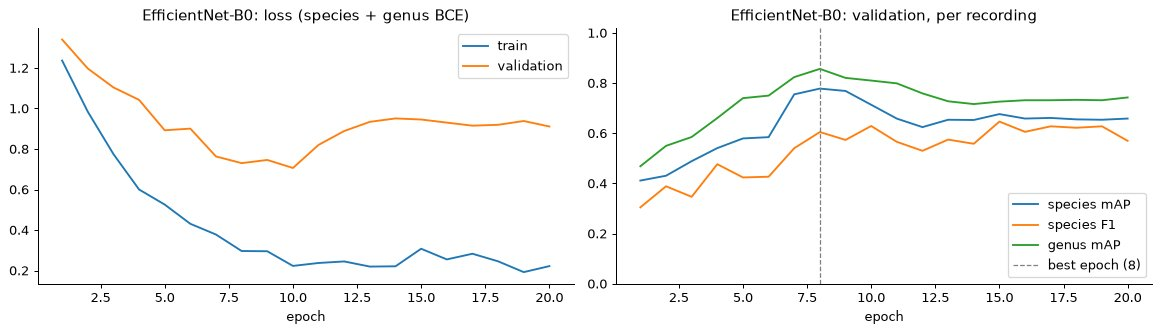

In [19]:
def plot_history(run_dir, title):
    history = pd.read_csv(run_dir / "history.csv")
    best = json.loads((run_dir / "best_val" / "metrics.json").read_text())
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    axes[0].plot(history.epoch, history.train_loss, label="train")
    axes[0].plot(history.epoch, history.val_loss, label="validation")
    axes[0].set(title=f"{title}: loss (species + genus BCE)", xlabel="epoch")
    axes[0].legend()
    for col, label in [("val_mAP", "species mAP"), ("val_f1", "species F1"), ("val_genus_mAP", "genus mAP")]:
        axes[1].plot(history.epoch, history[col], label=label)
    axes[1].axvline(best["epoch"], color="0.5", ls="--", lw=1, label=f"best epoch ({best['epoch']})")
    axes[1].set(title=f"{title}: validation, per recording", xlabel="epoch", ylim=(0, 1.02))
    axes[1].legend()
    fig.tight_layout()
    return best

best = plot_history(RUN_DIR, "EfficientNet-B0")
pd.Series(best, name="best validation epoch").to_frame().T.round(3)

The metrics, all computed per recording after max-pooling the chunk scores:

- **mAP**: average precision per class (how well the scores rank the
  recordings of that class above the others), averaged over classes. It does
  not depend on a threshold, which is why it is used to pick the best epoch.
- **F1**: precision and recall after thresholding the scores at
  `eval.threshold` (0.5).
- **AUROC**: area under the ROC curve, another threshold-free ranking score.

`best_val/` has the details for the best epoch: AP per class, and the classes
most often predicted together with the true class.

In [20]:
display(pd.read_csv(RUN_DIR / "best_val" / "per_class_species.csv").round(3))
display(pd.read_csv(RUN_DIR / "best_val" / "top_confusions.csv"))

,class,AP,n_recordings
0,Bombina_bombina,1.000,3
1,Bufo_bufo,1.000,3
2,Epidalea_calamita,0.592,3
3,Hyla_arborea,0.767,3
4,Hyla_meridionalis,0.532,3


,true_class,also_predicted,recordings
0,Epidalea_calamita,Hyla_meridionalis,2
1,Hyla_meridionalis,Bufo_bufo,2
2,Bombina_bombina,Epidalea_calamita,1
3,Bombina_bombina,Hyla_arborea,1
4,Hyla_arborea,Bufo_bufo,1
5,Hyla_arborea,Hyla_meridionalis,1
6,Hyla_meridionalis,Bombina_bombina,1
7,Hyla_meridionalis,Epidalea_calamita,1


## 8. Evaluate on the test set

The test recordings were not used for training or for picking the best
epoch, so they give an honest estimate. `evaluate.py` loads `best_model.pt`
and scores a folder (or, for a manifest dataset, a split value):

```bash
uv run evaluate.py --run runs/<run_name> --dir data/toy_frogs_chunks/test
```

It writes the same reports as for validation to `<run>/eval_test/`.

In [21]:
!{sys.executable} evaluate.py --run {RUN_DIR} --dir {TEST_DIR}

[test] 62 files, 15 recordings, 5 classes (smallest: 6, largest: 26)


{
  "loss": 1.0682157576084137,
  "mAP": 0.7492929339408875,
  "f1": 0.6555556058883667,
  "classes_scored": 5,
  "auroc": 0.8444444537162781,
  "recordings": 15,
  "genus_mAP": 0.8032828569412231,
  "genus_f1": 0.746666669845581,
  "genus_classes_scored": 4,
  "genus_auroc": 0.855555534362793
}
Reports written to runs/toy_frogs_20261106-174518/eval_test


In [22]:
display(pd.read_csv(RUN_DIR / "eval_test" / "per_class_species.csv").round(3))
pred = pd.read_csv(RUN_DIR / "eval_test" / "predictions.csv")
pred.round(3).head(6)

,class,AP,n_recordings
0,Bombina_bombina,0.589,3
1,Bufo_bufo,0.591,3
2,Epidalea_calamita,1.000,3
3,Hyla_arborea,1.000,3
4,Hyla_meridionalis,0.567,3


,recording,true_class,Bombina_bombina,Bufo_bufo,Epidalea_calamita,Hyla_arborea,Hyla_meridionalis
0,Bombina_bombina/inat_INAT158689550_673914,Bombina_bombina,0.928,0.098,0.451,0.184,0.080
1,Bombina_bombina/inat_INAT360223775_1941037,Bombina_bombina,0.733,0.817,0.271,0.246,0.167
2,Bombina_bombina/inat_INAT65905154_151721,Bombina_bombina,0.887,0.443,0.315,0.414,0.565
3,Bufo_bufo/inat_INAT153947064_635942,Bufo_bufo,0.935,0.716,0.480,0.326,0.246
4,Bufo_bufo/inat_INAT212881172_1012363,Bufo_bufo,0.850,0.176,0.253,0.357,0.206
5,Bufo_bufo/inat_INAT268934483_1364040,Bufo_bufo,0.158,0.990,0.103,0.087,0.064


`predictions.csv` has one row per test recording, with a score between 0 and
1 for every species. The model is **multi-label**: each species gets its own
sigmoid, so a recording can score high for several species (two frogs calling
together) or for none. Taking the highest-scoring species for each recording
gives a confusion matrix:

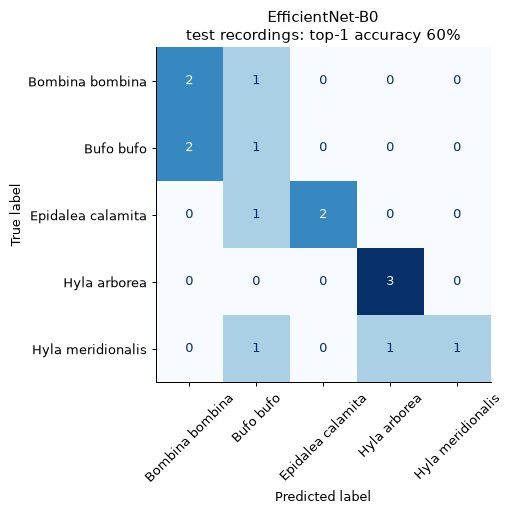

In [23]:
def plot_confusion(ax, pred, title):
    pred = pred.assign(predicted=pred[SPECIES].idxmax(axis=1))
    cm = confusion_matrix(pred.true_class, pred.predicted, labels=SPECIES)
    ConfusionMatrixDisplay(cm, display_labels=[s.replace("_", " ") for s in SPECIES]).plot(
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set(title=f"{title}\ntest recordings: top-1 accuracy {np.trace(cm) / cm.sum():.0%}")
    return pred

fig, ax = plt.subplots(figsize=(6.5, 5.8))
pred = plot_confusion(ax, pred, "EfficientNet-B0")
fig.tight_layout()

**Listen to the mistakes.** Listening to the recordings the model gets wrong
is the quickest way to find label errors, noisy recordings or missing classes.

In [24]:
def show_mistakes(pred, max_n=4):
    wrong = pred[pred.predicted != pred.true_class]
    if wrong.empty:
        print("No top-1 mistakes on the test recordings.")
    for _, r in wrong.head(max_n).iterrows():
        display(Markdown(f"**{r.recording}**: true *{r.true_class}*, predicted *{r.predicted}* "
                         f"(score {r[r.predicted]:.2f}; true class {r[r.true_class]:.2f})"))
        display(snippet(REC_DIR / "test" / f"{r.recording}.ogg"))

show_mistakes(pred)

**Bombina_bombina/inat_INAT360223775_1941037**: true *Bombina_bombina*, predicted *Bufo_bufo* (score 0.82; true class 0.73)

**Bufo_bufo/inat_INAT153947064_635942**: true *Bufo_bufo*, predicted *Bombina_bombina* (score 0.93; true class 0.72)

**Bufo_bufo/inat_INAT212881172_1012363**: true *Bufo_bufo*, predicted *Bombina_bombina* (score 0.85; true class 0.18)

**Epidalea_calamita/inat_INAT115610071_426507**: true *Epidalea_calamita*, predicted *Bufo_bufo* (score 0.93; true class 0.86)

## 9. A second model: Perch weights

Changing the model is one option. `perch_effnet_b3` is an EfficientNet-B3 that
starts from the Perch v2 weights (`checkpoints/perch_v2_backbone_timm.pt`,
shipped with the repository) instead of ImageNet. Section 5 already suggested
that its features separate the frogs better before any training. Everything
else stays the same:

```bash
uv run train.py --config configs/toy_frogs.yaml --set model.name=perch_effnet_b3
```

In [25]:
PERCH_DIR = Path(cfg["output_dir"]) / f"toy_frogs_perch_{STAMP}"
!{sys.executable} train.py --config {CONFIG} --set model.name=perch_effnet_b3 --set run_name={PERCH_DIR.name} | grep -v -E "^(Missing|Unexpected)"
!{sys.executable} evaluate.py --run {PERCH_DIR} --dir {TEST_DIR} > /dev/null

Run directory: runs/toy_frogs_perch_20261106-174518  |  device: cuda:0
[train] 152 files, 40 recordings, 5 classes (smallest: 26, largest: 34)
[val] 54 files, 15 recordings, 5 classes (smallest: 6, largest: 15)
5 classes, 4 genera
Model perch_effnet_b3: 10.7M trainable parameters


Epoch 1/20  train_loss 1.3724  val_loss 1.3437  mAP 0.7086  F1 0.2524  AUROC 0.8389  | genus mAP 0.4886  F1 0.4052  * best


Epoch 2/20  train_loss 1.3230  val_loss 1.2865  mAP 0.8700  F1 0.6648  AUROC 0.9278  | genus mAP 0.8656  F1 0.7803  * best


Epoch 3/20  train_loss 1.2590  val_loss 1.2132  mAP 0.9133  F1 0.7114  AUROC 0.9667  | genus mAP 0.9190  F1 0.8017  * best


Epoch 4/20  train_loss 1.1627  val_loss 1.1206  mAP 0.9133  F1 0.6900  AUROC 0.9667  | genus mAP 0.9190  F1 0.7359  (best 0.9133 @ 3)


Epoch 5/20  train_loss 1.0485  val_loss 1.0017  mAP 0.9244  F1 0.5943  AUROC 0.9722  | genus mAP 0.9250  F1 0.7192  * best


... (12 outputs left out)

Epoch 18/20  train_loss 0.3152  val_loss 0.4179  mAP 0.9400  F1 0.7262  AUROC 0.9778  | genus mAP 0.9607  F1 0.7907  (best 0.9567 @ 7)


Epoch 19/20  train_loss 0.3240  val_loss 0.4005  mAP 0.9400  F1 0.8076  AUROC 0.9778  | genus mAP 0.9732  F1 0.8507  (best 0.9567 @ 7)


Epoch 20/20  train_loss 0.3390  val_loss 0.4193  mAP 0.9400  F1 0.7739  AUROC 0.9778  | genus mAP 0.9607  F1 0.8292  (best 0.9567 @ 7)


Done. Best validation mAP 0.9567 at epoch 7: runs/toy_frogs_perch_20261106-174518/best_model.pt


,val mAP,test mAP,test F1,test AUROC,test genus mAP
ImageNet EfficientNet-B0,0.778,0.749,0.656,0.844,0.803
Perch EfficientNet-B3,0.957,0.967,0.777,0.983,0.986


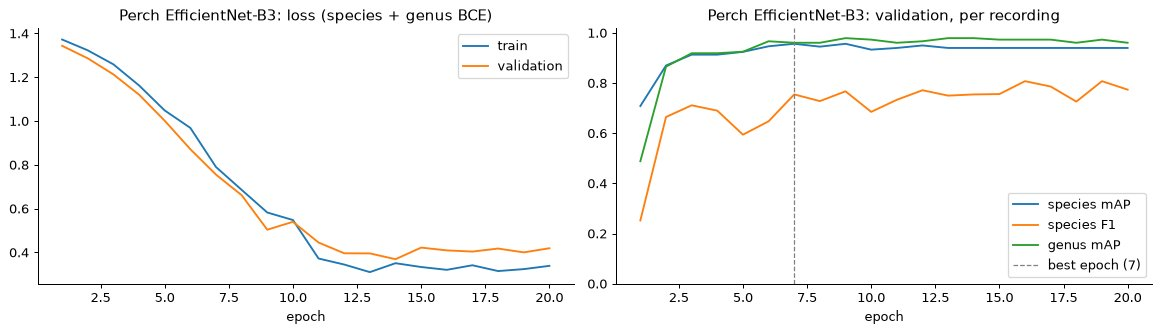

In [26]:
best_perch = plot_history(PERCH_DIR, "Perch EfficientNet-B3")

runs = {"ImageNet EfficientNet-B0": RUN_DIR, "Perch EfficientNet-B3": PERCH_DIR}
rows = {}
for name, d in runs.items():
    val = json.loads((d / "best_val" / "metrics.json").read_text())
    test = json.loads((d / "eval_test" / "metrics.json").read_text())
    rows[name] = {"val mAP": val["mAP"], "test mAP": test["mAP"], "test F1": test["f1"],
                  "test AUROC": test["auroc"], "test genus mAP": test["genus_mAP"]}
comparison = pd.DataFrame(rows).T.round(3)
comparison

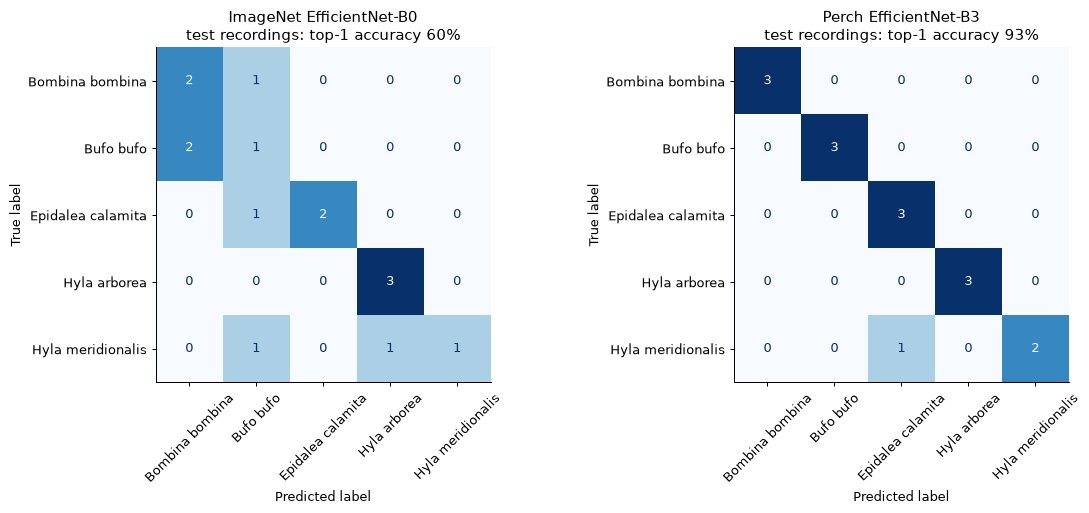

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
preds = {name: plot_confusion(ax, pd.read_csv(d / "eval_test" / "predictions.csv"), name)
         for ax, (name, d) in zip(axes, runs.items(), strict=True)}
fig.tight_layout()

**Which model to use?** Choose on the **validation** scores, not on the test
scores: the test set is only for the final report. If you try many models and
keep the one with the best test score, the test score is no longer an honest
estimate.

In [28]:
CHOSEN = comparison["val mAP"].idxmax()
MODEL_DIR = runs[CHOSEN]
print(f"best validation mAP: {CHOSEN} ({comparison.loc[CHOSEN, 'val mAP']:.3f}) -> {MODEL_DIR}")

best validation mAP: Perch EfficientNet-B3 (0.957) -> runs/toy_frogs_perch_20261106-174518


## 10. The data after training: UMAP again

The same projection as in section 5, now with the backbones of the trained
models. The training chunks (dots) are expected to separate: the models have
seen them. The interesting part is the **validation and test chunks**
(triangles and squares), which they have not seen.

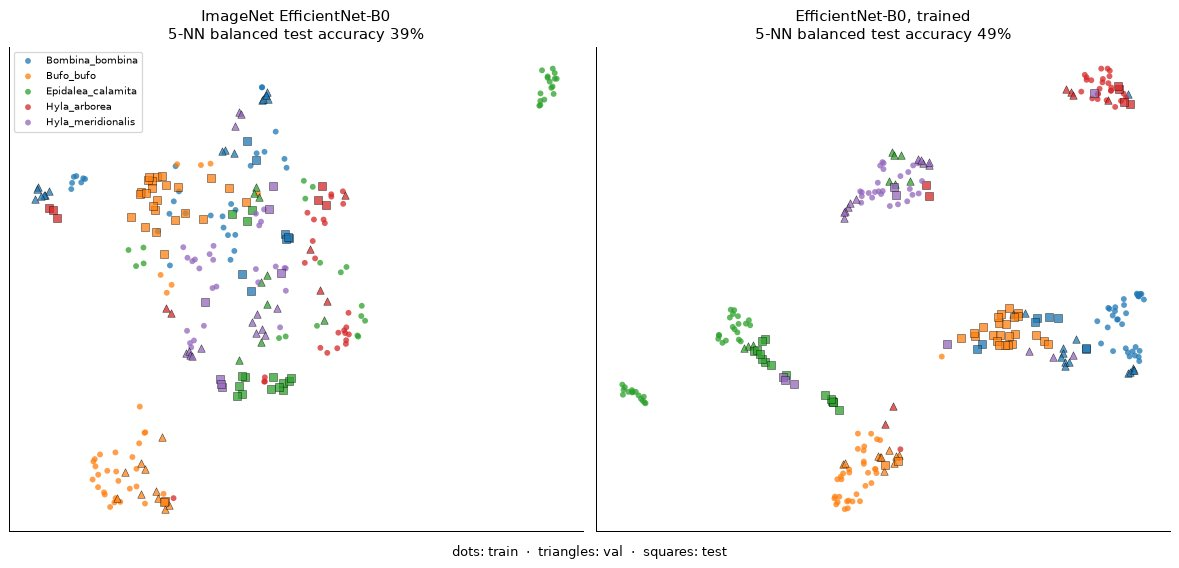

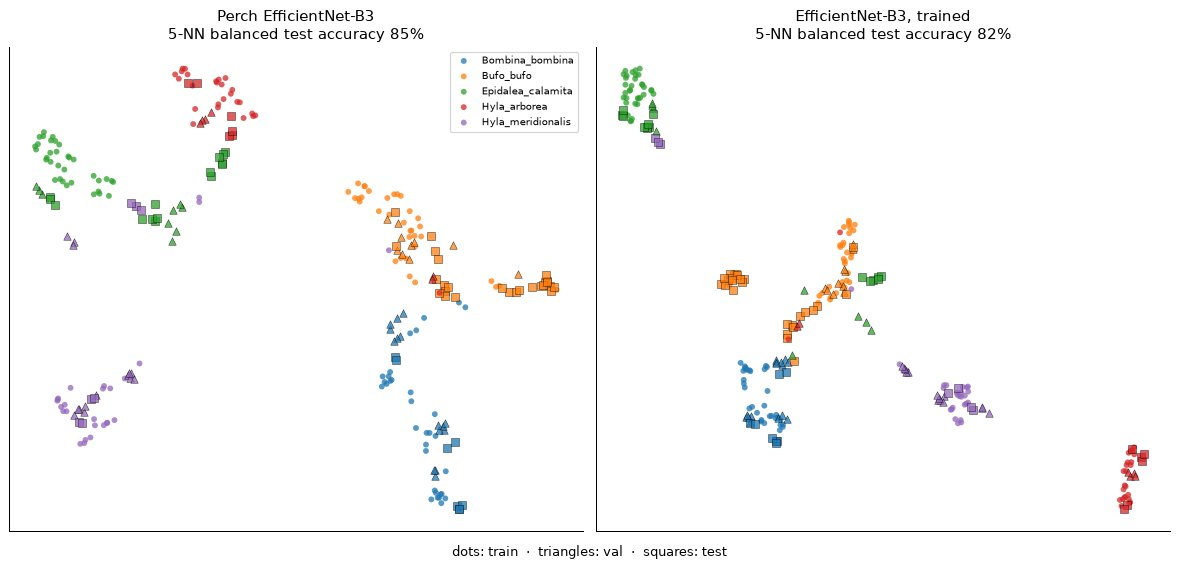

In [29]:
def load_run(run_dir, checkpoint="best_model.pt"):
    run_cfg = load_config(Path(run_dir) / "config.yaml")
    run_cfg["model"]["pretrained"] = False            # the weights come from the checkpoint
    labels = LabelSpace.load(Path(run_dir) / "labels.json")
    model = quiet(build_model, run_cfg, labels)
    model.load_state_dict(torch.load(Path(run_dir) / checkpoint, map_location="cpu", weights_only=True))
    return model.eval().to(device), labels, run_cfg

for name, d in runs.items():
    trained_name = name.split(" ", 1)[1] + ", trained"
    features[trained_name] = backbone_embeddings(load_run(d)[0], paths)
    maps[trained_name] = umap_2d(features[trained_name])

plot_maps(["ImageNet EfficientNet-B0", "EfficientNet-B0, trained"])
plot_maps(["Perch EfficientNet-B3", "EfficientNet-B3, trained"])

In [30]:
pd.Series({name: knn_accuracy(f) for name, f in features.items()}, name="5-NN balanced test accuracy").map("{:.0%}".format)

spectrogram statistics      17%
ImageNet EfficientNet-B0    39%
Perch EfficientNet-B3       85%
EfficientNet-B0, trained    49%
EfficientNet-B3, trained    82%
Name: 5-NN balanced test accuracy, dtype: str

- The **ImageNet EfficientNet-B0** map now groups the chunks by species. The
  validation and test chunks are less well placed than the training chunks,
  and the test chunks of the long *Bufo bufo* recording land next to *Bombina
  bombina*: the same mistake as in the confusion matrix of section 8.
- The **Perch EfficientNet-B3** map was already well separated, and training
  on 40 recordings does not improve its 5-NN score. What training adds for
  this model are the classification heads, which turn the good features into
  the high test scores of section 9.

With little data, start from weights trained on similar sounds.
(In a UMAP plot the groups are meaningful; the distances between groups are not.)

## 11. Use the model on a whole recording

To classify a recording of any length, do what evaluation does: cut it into
5 s chunks the same way as `prepare_chunks.py`, score each chunk, and take the
maximum over the chunks. The
per-chunk scores also show *when* each species is calling.

We take the chosen model and the longest test recording.

Bufo_bufo            0.723
Bombina_bombina      0.635
Hyla_meridionalis    0.450
Hyla_arborea         0.310
Epidalea_calamita    0.285
Name: recording score (max over chunks), dtype: float32

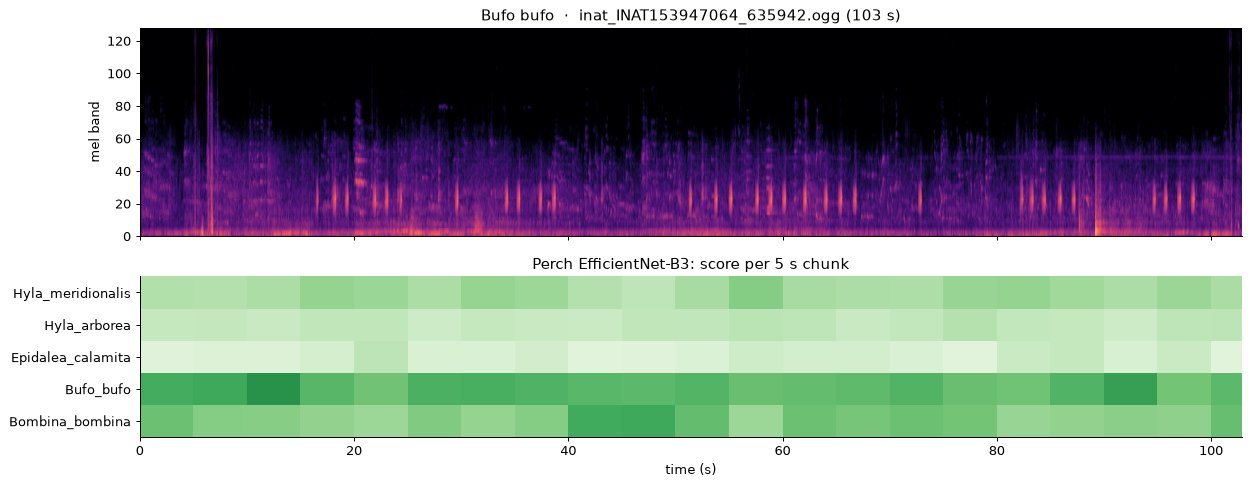

In [31]:
model, labels, run_cfg = load_run(MODEL_DIR)

@torch.no_grad()
def predict_recording(model, x, sr=SR, chunk_seconds=CHUNK_SECONDS, min_chunk_seconds=2.0):
    # Scores per chunk (n_chunks, n_species) and per recording (n_species,).
    # Chunks as in prepare_chunks.py: a leftover of at least min_chunk_seconds is tiled and kept.
    n = int(chunk_seconds * sr)
    starts = list(range(0, max(len(x) - n, 0) + 1, n))
    if len(x) - (starts[-1] + n) >= min_chunk_seconds * sr:
        starts.append(starts[-1] + n)
    chunks = np.stack([fix_length(x[s:s + n], n, random_crop=False) for s in starts])
    out = model(torch.as_tensor(chunks, dtype=torch.float32, device=device))
    species_logits = out[0] if isinstance(out, tuple) else out
    per_chunk = torch.sigmoid(species_logits.float()).cpu().numpy()
    return per_chunk, per_chunk.max(axis=0)

def predict_file(model, path, top=3):
    x, _ = librosa.load(path, sr=SR, mono=True)
    _, scores = predict_recording(model, x)
    order = np.argsort(scores)[::-1][:top]
    return pd.DataFrame({"species": [labels.species[i] for i in order], "score": scores[order].round(3)})

r = recs[recs.split == "test"].sort_values("duration_s").iloc[-1]
x, _ = librosa.load(r.path, sr=SR, mono=True)
per_chunk, scores = predict_recording(model, x)

fig, axes = plt.subplots(2, 1, figsize=(14, 5.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
axes[0].imshow(logmel_db(x), origin="lower", aspect="auto", cmap="magma", vmin=-80, extent=[0, len(x) / SR, 0, 128])
axes[0].set(title=f"{r.latin}  ·  {Path(r.path).name} ({len(x) / SR:.0f} s)", ylabel="mel band")
axes[1].imshow(per_chunk.T, aspect="auto", cmap="Greens", vmin=0, vmax=1, origin="lower",
               extent=[0, len(per_chunk) * CHUNK_SECONDS, -0.5, len(labels.species) - 0.5])
axes[1].set(yticks=range(len(labels.species)), yticklabels=labels.species, xlabel="time (s)",
            title=f"{CHOSEN}: score per 5 s chunk", xlim=(0, len(x) / SR))
fig.tight_layout()
pd.Series(scores.round(3), index=labels.species, name="recording score (max over chunks)").sort_values(ascending=False)

`predict_file` does the same for any audio file on disk, at any sample rate:

In [32]:
predict_file(model, recs[recs.split == "test"].path.iloc[0])

,species,score
0,Bombina_bombina,0.752
1,Bufo_bufo,0.405
2,Hyla_arborea,0.300


## 12. Next steps: your own data

1. **Put your recordings in class folders** (like `data/toy_frogs/recordings`)
   or list them in a CSV with a label and a split column (like
   `data/toy_frogs/recordings.csv`), and cut them into chunks with
   `tools/prepare_chunks.py` as in section 2. README section 2 explains both
   layouts and what the tool writes.

2. **Copy a config** (`configs/example_folders.yaml`, `configs/example_manifest.yaml`,
   or this notebook's `configs/toy_frogs.yaml`) and set the paths.
   With real amounts of data, use more epochs and `train.early_stop_patience`.

3. **Try several models** with `--set model.name=...` (README section 4):
   `effnet` with a bigger `model.backbone`, `perch_effnet_b3`, or `passt` (an
   AudioSet transformer). Compare them on the validation set and report the
   test score of the one you choose.

4. **Not species?** Call types, dialects or individuals train the same way;
   see "Not only species" in the README.